# MLOps Tutorial: Keeping a Model Alive When the Data Drifts

Training a model is the easy part. The hard part starts **after deployment**: the world keeps changing, the model does not. This notebook simulates that situation and lets you build the safeguards that production ML teams use every day.

## What you will learn

| # | Concept | The question it answers |
|:-:|---|---|
| 1 | **Data drift** | Why is a model that was good last month worse today? |
| 2 | **Monitoring** | How do I notice the degradation before my users do? |
| 3 | **Retraining** | How do I update a model with fresh data, and how much should the past still count? |
| 4 | **Champion / Challenger** | How do I compare the live model with a candidate replacement? |
| 5 | **Canary release** | How do I roll out the candidate to a small slice of traffic first? |
| 6 | **Promotion rule** | When has the candidate earned the right to replace the champion? |

## The scenario

You run a service that makes a yes/no prediction for every request: *will this customer buy? is this transaction fraud?* You trained a model once, deployed it, and now you simulate **50 rounds** of production traffic. Think of each round as one day. Every day the data shifts a little further away from what the model saw at training time.

Your job is to implement the pieces that keep the system healthy:

- a **challenger** model that is retrained on recent data,
- **canary routing** that lets the challenger serve a small share of traffic,
- a **promotion rule** that replaces the champion only when the challenger is reliably better.

<div style="border-left:6px solid #1f77b4; background:#eef5fb; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">📖 How to use this notebook</b><br>
<table style="margin-top:8px;">
<tr><td style="padding:4px 12px 4px 0;"><b>▶ run this</b></td><td>Helper cells. Run them, no need to edit (in Colab they are collapsed, just press play).</td></tr>
<tr><td style="padding:4px 12px 4px 0;"><b>🎯 Task</b></td><td>Five gaps for you to fill, each with hints. Replace every <code>...</code> with your code.</td></tr>
<tr><td style="padding:4px 12px 4px 0;"><b>✅ Check</b></td><td>What you should see if your code is right.</td></tr>
<tr><td style="padding:4px 12px 4px 0;"><b>🧪 Experiments</b></td><td>Part 10. Save time for it, that is where the intuition comes from.</td></tr>
</table>
<p style="margin-bottom:0;">A <code>...</code> left behind will cause an error mentioning <code>ellipsis</code> sooner or later.</p>
</div>

## Part 1: Setup and Helper Functions

The cell below imports the libraries and defines a few helpers. Everything in here is **▶ run this**; you do not need to read it now. You may want to come back to `generate_batch` after Part 3.

| Helper | What it does |
|---|---|
| `generate_batch(angle, size)` | Produces one batch of synthetic data, rotated by `angle` radians. This is how drift is injected (Part 3). |
| `drift_schedule(round, total)` | How much extra drift arrives in a given round. |
| `plot_sample_data`, `plot_drift_snapshot`, `plot_drift_effect` | Visualise the data and what drift does to a fixed model. |
| `plot_model_accuracies` | The result plot for Part 7. |

In [21]:
# @title Imports and helper functions (run this!) {display-mode: "form"}
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


def generate_batch(angle=0.0, size=400, rng=None):
    """
    Generate a batch of 2D binary classification data, with drift.

    Before drift, class 0 is a Gaussian blob centred at (0, 0) and class 1
    a Gaussian blob centred at (2, 2). Drift is injected by rotating the
    whole dataset (both classes) around the origin by `angle` radians.
    As the angle grows over time the data distribution moves, which is
    exactly what happens in production when the world changes.

    The rows are shuffled, so any slice of the batch is a random sample
    of both classes (this matters for the canary split later).

    Parameters
    ----------
    angle : float   drift, expressed as a rotation angle in radians
    size  : int     number of samples (split equally between the classes)

    Returns
    -------
    X : np.ndarray of shape (size, 2)   features
    y : np.ndarray of shape (size,)     labels (0 or 1)
    """
    rng = np.random.default_rng() if rng is None else rng
    half = size // 2
    X0 = rng.normal(loc=[0.0, 0.0], scale=[1.0, 1.0], size=(half, 2))
    X1 = rng.normal(loc=[2.0, 2.0], scale=[1.0, 1.0], size=(half, 2))
    X = np.vstack([X0, X1])
    y = np.concatenate([np.zeros(half, dtype=int), np.ones(half, dtype=int)])

    # Rotate the whole dataset around the origin
    rotation = np.array([
        [np.cos(angle), -np.sin(angle)],
        [np.sin(angle),  np.cos(angle)],
    ])
    X = X @ rotation.T

    # Shuffle so the batch is not sorted by class
    order = rng.permutation(len(y))
    return X[order], y[order]


def drift_schedule(round_idx, total_rounds, step_scale=0.05, rng=None):
    """
    How much extra drift (rotation, in radians) arrives in a given round.

    The step is random, but has a positive mean (0.03 rad), so drift
    accumulates over time. The noise gets larger in later rounds, which
    makes the second half of the simulation bumpier than the first.
    """
    rng = np.random.default_rng() if rng is None else rng
    return rng.normal(loc=0.03, scale=step_scale * (1 + round_idx / total_rounds))


def plot_sample_data(X, y, title="Sample data (no drift)"):
    """Scatter plot of one batch, coloured by class."""
    plt.figure(figsize=(6, 6))
    plt.scatter(X[y == 0, 0], X[y == 0, 1], alpha=0.5, s=25, label="Class 0")
    plt.scatter(X[y == 1, 0], X[y == 1, 1], alpha=0.5, s=25, label="Class 1")
    plt.xlabel("Feature 1"); plt.ylabel("Feature 2"); plt.title(title)
    plt.axis("equal"); plt.legend(); plt.grid(True, alpha=0.3)
    plt.show()


def plot_drift_snapshot(angle, size=400, rng=None):
    """
    One batch at a given drift angle, together with the ideal day-0 decision
    line (the line halfway between the two class centres, x + y = 2).
    """
    rng = np.random.default_rng(0) if rng is None else rng
    X, y = generate_batch(angle=angle, size=size, rng=rng)
    pred = (X[:, 0] + X[:, 1] > 2).astype(int)
    acc = accuracy_score(y, pred)
    plt.figure(figsize=(6, 6))
    plt.fill_between([-6, 8], [8, -6], [-6, -6], color="#1f77b4", alpha=0.08)
    plt.fill_between([-6, 8], [8, -6], [8, 8], color="#ff7f0e", alpha=0.08)
    plt.plot([-6, 8], [8, -6], "k--", lw=1.5, label="decision line learned at day 0")
    plt.scatter(X[y == 0, 0], X[y == 0, 1], alpha=0.6, s=25, label="Class 0")
    plt.scatter(X[y == 1, 0], X[y == 1, 1], alpha=0.6, s=25, label="Class 1")
    plt.xlim(-6, 6); plt.ylim(-6, 6)
    plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
    plt.title(f"drift = {angle:.2f} rad ({np.degrees(angle):.0f}°)   →   accuracy of the day-0 line = {acc:.2f}")
    plt.legend(loc="lower left"); plt.grid(True, alpha=0.3)
    plt.show()


def plot_drift_effect(model, angles, size=400, rng=None):
    """
    Show the same model's decision boundary against data at several
    drift angles. The boundary stays fixed, the data rotates away from it.
    """
    rng = np.random.default_rng(0) if rng is None else rng
    fig, axes = plt.subplots(1, len(angles), figsize=(5 * len(angles), 5))
    xx, yy = np.meshgrid(np.linspace(-6, 6, 200), np.linspace(-6, 6, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    for ax, angle in zip(np.atleast_1d(axes), angles):
        X, y = generate_batch(angle=angle, size=size, rng=rng)
        acc = accuracy_score(y, model.predict(X))
        ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], alpha=0.15)
        ax.scatter(X[y == 0, 0], X[y == 0, 1], alpha=0.5, s=20, label="Class 0")
        ax.scatter(X[y == 1, 0], X[y == 1, 1], alpha=0.5, s=20, label="Class 1")
        ax.set_title(f"drift angle = {angle:.2f} rad  →  accuracy = {acc:.2f}")
        ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.grid(True, alpha=0.3)
    axes[0].legend()
    plt.tight_layout(); plt.show()


def plot_model_accuracies(acc_A_hist, acc_B_hist, retrain_rounds, promotions, rounds):
    """Accuracy of both models per round, with retrain (:) and promotion (--) markers."""
    plt.figure()
    plt.plot(range(1, rounds + 1), acc_A_hist, label="Model A (champion, never retrained)", linewidth=2)
    plt.plot(range(1, rounds + 1), acc_B_hist, label="Model B (challenger, retrained)", linewidth=2)
    for rr in retrain_rounds:
        plt.axvline(rr, linestyle=":", alpha=0.6, color="gray")
    for pr in promotions:
        plt.axvline(pr, linestyle="--", alpha=0.8, color="red", linewidth=1.5)
    plt.title("Accuracy on the full batch per round   (':' = B retrained,  '--' = B promoted)")
    plt.xlabel("Round"); plt.ylabel("Accuracy"); plt.ylim(0.4, 1.0)
    plt.legend(loc="lower left"); plt.grid(True, alpha=0.3); plt.show()


plt.rcParams["figure.figsize"] = (10, 5)
print("✓ Setup complete!")

✓ Setup complete!


## Part 2: Configuration

These parameters control the simulation. Read them once now; in Part 10 you will come back and change them.

| Group | Parameter | Default | Meaning |
|---|---|:-:|---|
| **Simulation** | `ROUNDS` | 50 | Number of time periods we simulate (think: days) |
| | `BATCH_SIZE` | 400 | Number of requests that arrive each round |
| | `SEED` | 42 | Random seed, so a run can be reproduced |
| **Retraining Model B** | `RETRAINING_FREQUENCY` | 5 | Retrain the challenger every N rounds |
| | `FRESHNESS_RELEVANCE` | 0.8 | How strongly recent data is favoured when retraining. `0.0` = all data counts equally, `1.0` = only the newest batch counts (details in Part 5) |
| **Promotion** | `PROMOTION_THRESHOLD` | 0.02 | B must beat A by at least this much accuracy (absolute: `0.02` = 2 percentage points) |
| | `PROMOTION_PATIENCE` | 3 | ... and must do so for this many rounds **in a row** |
| **Canary** | `CANARY_FRACTION` | 0.2 | Share of each round's traffic routed to the challenger while it is on trial |

In [22]:
# --- Simulation ---
ROUNDS = 50          # number of deployment rounds ("days")
BATCH_SIZE = 400     # requests per round
SEED = 42            # change to see a different random run

# --- Retraining the challenger (Model B) ---
RETRAINING_FREQUENCY = 5    # retrain every N rounds
FRESHNESS_RELEVANCE = 0.8   # 0.0 = treat all data equally, 1.0 = only the newest data matters

# --- Promotion rule ---
PROMOTION_THRESHOLD = 0.02  # B must beat A by this absolute accuracy margin ...
PROMOTION_PATIENCE = 3      # ... for this many consecutive rounds

# --- Canary release ---
CANARY_FRACTION = 0.2       # share of traffic served by the challenger while on trial

rng = np.random.default_rng(SEED)
print(f"✓ Configuration set: {ROUNDS} rounds, retraining every {RETRAINING_FREQUENCY} rounds, "
      f"canary = {CANARY_FRACTION:.0%} of traffic")

✓ Configuration set: 50 rounds, retraining every 5 rounds, canary = 20% of traffic


## Part 3: Understanding the Data

We use a **synthetic** dataset on purpose: it is small, fast, and we control exactly how it drifts. That lets you focus on the MLOps mechanics rather than on data wrangling.

### The task

**Binary classification**: every data point has two input features (think of them as two measurements, like *amount* and *time of day*) and a label that is either 0 or 1. Think of it as *will this customer buy?* or *is this transaction fraudulent?* The model's job is to guess the label from the two features.

### What the data looks like

If you plot each point with feature 1 on the x-axis and feature 2 on the y-axis, each class forms a **cloud of points** around a centre. Points are dense near the centre and sparser further out, like darts around a bullseye. Statisticians call such a cloud a *Gaussian blob*; all you need to know is that it is a round cloud with a centre and some spread.

| Class | Centre of the cloud (before drift) |
|:-:|:-:|
| **0** | (0, 0) |
| **1** | (2, 2) |

Both clouds have the same spread: most points lie within 2 units of their centre. Since the centres are only about 2.8 units apart, the two clouds overlap at the edges, so even a perfect model cannot reach 100 % accuracy. A good model separates them with a straight line between the two centres, and that is exactly what a **logistic regression** does.

### How drift is simulated

<div style="border-left:6px solid #d62728; background:#fdeeee; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">📌 Definition: data drift</b><br>
<p style="margin:6px 0;"><b>Data drift is when the data your model sees in production no longer looks like the data it was trained on.</b></p>
The model's parameters have not changed, but the world has: customers behave differently, prices move, fraudsters adapt, sensors age.
A model is only as good as the match between its training data and today's data. When that match breaks down, accuracy decays <i>silently</i>: the model keeps producing predictions, they are just wrong more often.
</div>

In this notebook we simulate drift by **rotating the whole dataset around the origin**, a little more every round. The two clouds travel around the origin together, so the straight line that separated them at day 0 is in the wrong place more and more.

Watch what happens to the accuracy in the title as the clouds rotate away from the dashed line, which never moves:

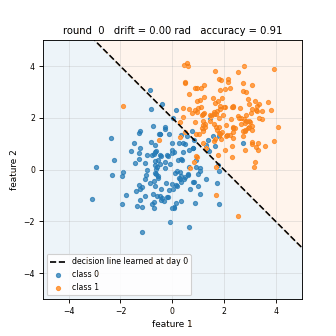

Each frame is one round. The dashed line is the decision line a model learned at day 0: everything below it is predicted as class 0, everything above as class 1. At round 0 it separates the clouds nicely. By round 24 half of class 1 has crossed to the wrong side. By round 47 the clouds have swapped places and the line is worse than a coin flip.

<div style="border-left:6px solid #1f77b4; background:#eef5fb; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">💡 The key point</b><br>
<b>The model did not get worse. The world moved.</b> The line is exactly as good as it was on day 0, for the day 0 data. Nobody retrained it, nobody broke it, and yet it is now useless.
That is the problem the rest of this notebook solves.
</div>

Batch shape: (400, 2)  →  400 samples, 2 features
Class balance: 200 × class 0, 200 × class 1


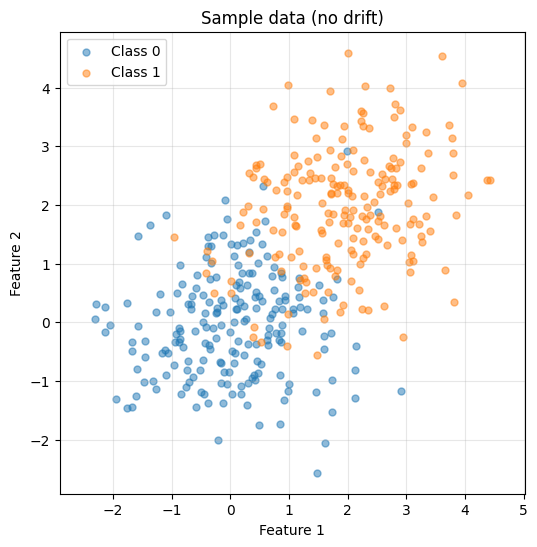

In [3]:
# @title Generate and plot one batch with no drift (run this!) {display-mode: "form"}
X_sample, y_sample = generate_batch(angle=0.0, size=BATCH_SIZE, rng=rng)

print(f"Batch shape: {X_sample.shape}  →  {X_sample.shape[0]} samples, {X_sample.shape[1]} features")
print(f"Class balance: {np.sum(y_sample == 0)} × class 0, {np.sum(y_sample == 1)} × class 1")

plot_sample_data(X_sample, y_sample)

### Try it yourself: drift at a chosen angle

Pick a drift angle with the slider (in Colab) or by editing the number, then run the cell. The dashed line is again the day-0 decision line. At what angle does accuracy drop below 0.7? When does it fall to a coin flip?

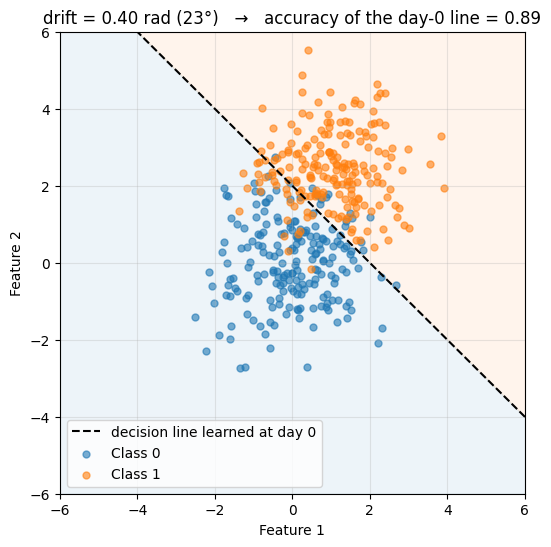

In [24]:
angle = 0.4  # @param {type:"slider", min:0, max:3.1, step:0.1}

plot_drift_snapshot(angle, rng=rng)

## Part 4: Initial Training (before going live)

This is "day 0". We train the model that will go into production, and we also prepare its future replacement.

| Step | What | Who does it |
|:-:|---|:-:|
| 1 | Generate 2000 training samples, no drift yet | provided |
| 2 | Train **Model A, the Champion**. This is the model that goes live. It will **never be retrained**, which is what happens to a lot of real models once nobody looks at them anymore. | provided |
| 3 | Train **Model B, the Challenger**. At day 0 it is an identical copy of A. Later it will be retrained on fresh data, and we will test whether it deserves to replace A. | 🎯 you |
| 4 | Evaluate both on a holdout set to record a baseline | 🎯 you |

In [25]:
# Step 1: training data for "day 0" (no drift)
X_init, y_init = generate_batch(angle=0.0, size=2000, rng=rng)
print(f"✓ Generated {len(y_init)} training samples")

✓ Generated 2000 training samples


In [26]:
# Step 2: train Model A (the Champion) - PROVIDED FOR YOU
model_A = LogisticRegression(max_iter=1000)
model_A.fit(X_init, y_init)
print("✓ Model A (champion) trained")

✓ Model A (champion) trained


<div style="border-left:6px solid #e8740c; background:#fff4e6; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">🎯 Task 1 of 5 — Train Model B, the Challenger</b><br>
At day 0, Model B is trained exactly like Model A, on the same data.
<ul style="margin-bottom:0;">
<li>Create a <code>LogisticRegression(max_iter=1000)</code>, like Model A.</li>
<li>Fit it on <code>X_init</code> and <code>y_init</code>.</li>
</ul>
</div>

In [27]:
# Step 3: train Model B (the Challenger) - YOUR CODE HERE! 🎯
model_B = LogisticRegression(max_iter=1000)
model_B.fit(X_init, y_init)

print("✓ Model B (challenger) trained on the same initial data as Model A")

✓ Model B (challenger) trained on the same initial data as Model A


In [28]:
# @title Initialise Model B's training history (run this!) {display-mode: "form"}
# Every batch Model B sees in production will be appended here, so that it
# can be retrained on "everything so far". `w_hist` holds one weight per
# sample; retraining will down-weight old samples (see Part 5).
X_hist = X_init.copy()
y_hist = y_init.copy()
w_hist = np.ones_like(y_hist, dtype=float)   # all samples equally important for now

print(f"✓ Training history initialised with {len(y_hist)} samples")

✓ Training history initialised with 2000 samples


<div style="border-left:6px solid #e8740c; background:#fff4e6; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">🎯 Task 2 of 5 — Baseline accuracy of Model B</b><br>
Evaluate Model B on the holdout set <code>X_hold, y_hold</code>, the same way Model A is evaluated in the cell.
<ul style="margin-bottom:0;">
<li>Pattern: <code>accuracy_score(true_labels, predicted_labels)</code></li>
<li>Predictions come from <code>model_B.predict(X_hold)</code></li>
</ul>
</div>

In [29]:
# Step 4: baseline evaluation on a holdout set (no drift)
X_hold, y_hold = generate_batch(angle=0.0, size=1000, rng=rng)

# Model A - PROVIDED FOR YOU
base_acc_A = accuracy_score(y_hold, model_A.predict(X_hold))

# Model B - YOUR CODE HERE! 🎯
base_acc_B = accuracy_score(y_hold, model_B.predict(X_hold))

print("=" * 50)
print("BASELINE ACCURACY (no drift)")
print("=" * 50)
print(f"Model A (champion):   {base_acc_A:.3f}")
print(f"Model B (challenger): {base_acc_B:.3f}")
print("=" * 50)

BASELINE ACCURACY (no drift)
Model A (champion):   0.919
Model B (challenger): 0.919


<div style="border-left:6px solid #2ca02c; background:#eefaf0; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">✅ Check your work</b><br>
<ul>
<li>Both models should have <b>exactly the same</b> accuracy. They are identical right now.</li>
<li>The accuracy should be roughly between 0.85 and 0.95. The two blobs overlap, so 100 % is not possible.</li>
</ul>
<p style="margin-bottom:0;">If something looks off, go back and check Tasks 1 and 2.</p>
</div>

### What drift will do to Model A

Before we go live, let's look at what happens to Model A's decision boundary as the data rotates. The shaded regions are what Model A predicts; the dots are data at increasing drift angles. **The boundary never moves. The data does.**

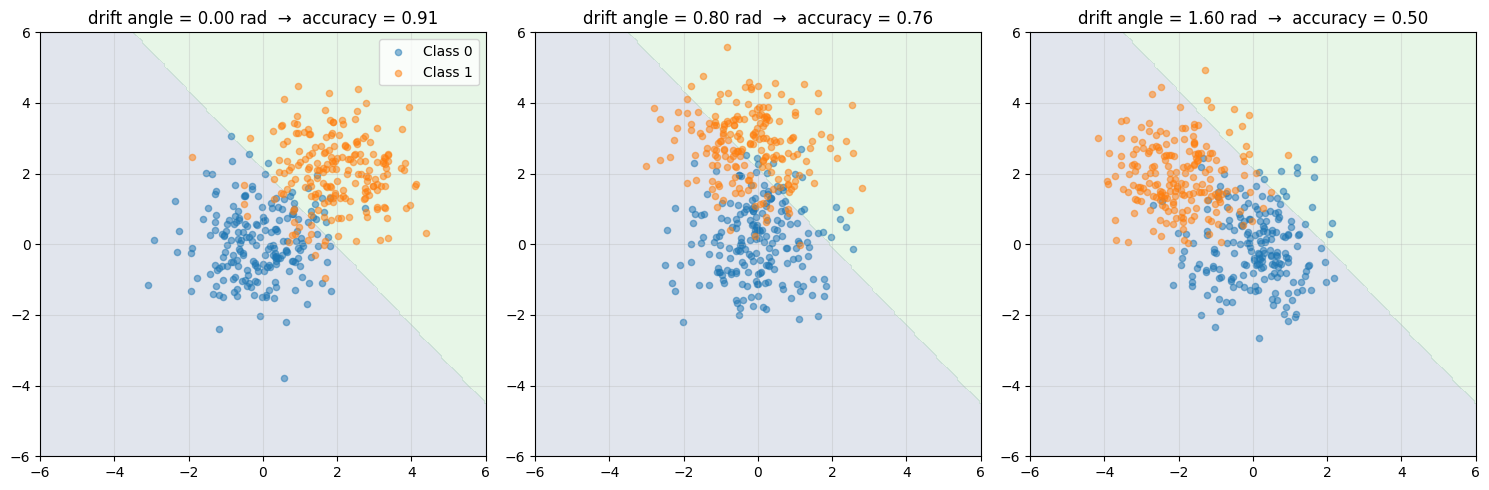

In [14]:
# @title Model A's fixed boundary vs. drifting data (run this!) {display-mode: "form"}
plot_drift_effect(model_A, angles=[0.0, 0.8, 1.6])

## Part 5: Going Live – the Deployment Strategy

We now simulate 50 rounds of production. The loop combines four mechanisms. Here is each one in two lines.

<table style="border-collapse:separate; border-spacing:0; width:100%;">
<tr>
<td style="vertical-align:top; width:50%; padding:6px;"><div style="border-top:5px solid #1f77b4; background:#f7f7f9; color:#111; padding:10px 14px; border-radius:6px; height:100%;"><b style="font-size:1.05em;">🥇 Champion / Challenger</b><br><span><b>Model A</b> (champion) is the trusted live model, never retrained. <b>Model B</b> (challenger) is the candidate, retrained on recent data. Every round both are scored on the full batch.</span><br><span style="color:#555;"><b>Guards against:</b> replacing a model on a hunch instead of on evidence</span></div></td><td style="vertical-align:top; width:50%; padding:6px;"><div style="border-top:5px solid #e8740c; background:#f7f7f9; color:#111; padding:10px 14px; border-radius:6px; height:100%;"><b style="font-size:1.05em;">🐤 Canary release</b><br><span>The challenger serves only a small slice of traffic (<code>CANARY_FRACTION</code> = 20 %). The champion serves the rest.</span><br><span style="color:#555;"><b>Guards against:</b> a bad new model hurting all users at once</span></div></td>
</tr>
<tr>
<td style="vertical-align:top; width:50%; padding:6px;"><div style="border-top:5px solid #2ca02c; background:#f7f7f9; color:#111; padding:10px 14px; border-radius:6px; height:100%;"><b style="font-size:1.05em;">🏆 Promotion rule</b><br><span>B replaces A only if it is <b>clearly</b> better (by ≥ <code>PROMOTION_THRESHOLD</code>) <b>and consistently</b> so (<code>PROMOTION_PATIENCE</code> rounds in a row). Then B serves all traffic.</span><br><span style="color:#555;"><b>Guards against:</b> promoting on one lucky round</span></div></td><td style="vertical-align:top; width:50%; padding:6px;"><div style="border-top:5px solid #9467bd; background:#f7f7f9; color:#111; padding:10px 14px; border-radius:6px; height:100%;"><b style="font-size:1.05em;">🔄 Retraining with freshness</b><br><span>Every <code>RETRAINING_FREQUENCY</code> rounds, B is retrained on everything seen so far, with recent samples weighted more (chart below).</span><br><span style="color:#555;"><b>Guards against:</b> the challenger going stale like the champion</span></div></td>
</tr>
</table>

### Where does the traffic go?

<table style="border-collapse:collapse; margin:8px 0; color:#111;">
<tr>
<td style="padding:10px 14px; background:#f0f0f0; border-radius:6px; text-align:center;"><b>400 requests</b><br><span style="font-size:0.9em;">arrive this round</span></td>
<td style="padding:0 10px; font-size:1.6em;">→</td>
<td>
  <table style="border-collapse:collapse;">
  <tr><td style="padding:6px 12px; background:#dbe9f6; border-left:5px solid #1f77b4; border-radius:4px;"><b>80 %</b> → Model A (champion)</td></tr>
  <tr><td style="height:6px;"></td></tr>
  <tr><td style="padding:6px 12px; background:#fde7d2; border-left:5px solid #e8740c; border-radius:4px;"><b>20 %</b> → Model B (challenger, on trial)</td></tr>
  </table>
</td>
<td style="padding:0 10px; font-size:1.6em;">→</td>
<td style="padding:10px 14px; background:#eefaf0; border-left:5px solid #2ca02c; border-radius:6px;"><b>Served accuracy</b><br><span style="font-size:0.9em;">= 0.8 × acc<sub>A</sub> + 0.2 × acc<sub>B</sub><br>what users as a whole experienced</span></td>
</tr>
</table>

Once B is promoted the split disappears: B serves 100 % and the served accuracy is simply B's accuracy.

### How fast does old data fade?

At every retraining, existing samples are multiplied by `(1 − FRESHNESS_RELEVANCE)` and the new batch comes in with weight `FRESHNESS_RELEVANCE`. With the default 0.8, this is what the training set looks like at the fourth retraining:

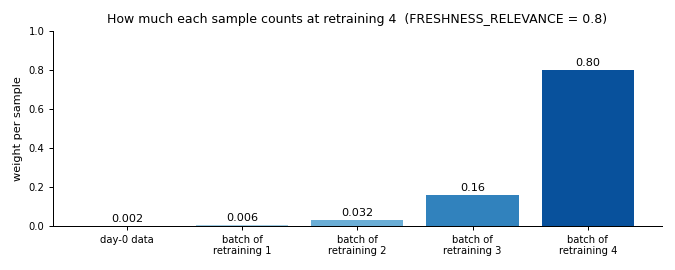

The newest batch dominates, the previous one still counts a bit, and anything older is nearly forgotten. This is **exponential forgetting**. Two extremes to keep in mind: at `0.0` B never adapts and behaves like A; at `1.0` B knows only the latest batch.

<div style="border-left:6px solid #1f77b4; background:#eef5fb; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">🔁 One round, step by step</b><br>
<div style="line-height:2.2;">
<span style="background:#fff; border:1px solid #c9daea; border-radius:14px; padding:3px 10px; white-space:nowrap;">① drift grows</span> →
<span style="background:#fff; border:1px solid #c9daea; border-radius:14px; padding:3px 10px; white-space:nowrap;">② batch arrives</span> →
<span style="background:#fff; border:1px solid #c9daea; border-radius:14px; padding:3px 10px; white-space:nowrap;">③ split 80 / 20</span> →
<span style="background:#fff; border:1px solid #c9daea; border-radius:14px; padding:3px 10px; white-space:nowrap;">④ each model serves its slice</span> →
<span style="background:#fff; border:1px solid #c9daea; border-radius:14px; padding:3px 10px; white-space:nowrap;">⑤ score both on the full batch</span> →
<span style="background:#fff; border:1px solid #c9daea; border-radius:14px; padding:3px 10px; white-space:nowrap;">⑥ promotion check</span> →
<span style="background:#fff; border:1px solid #c9daea; border-radius:14px; padding:3px 10px; white-space:nowrap;">⑦ every 5 rounds: retrain B</span>
</div>
</div>

In [30]:
# @title Tracking variables (run this!) {display-mode: "form"}
drift_values = []      # accumulated drift per round
acc_A_hist = []        # Model A accuracy on the full batch, per round
acc_B_hist = []        # Model B accuracy on the full batch, per round
served_acc_hist = []   # what users experienced (blend of A and B), per round
retrain_rounds = []    # rounds in which Model B was retrained
promotions = []        # rounds in which Model B was promoted

promoted = False       # has B replaced A?
consecutive_wins = 0   # how many rounds in a row B has beaten A by the threshold
mu = 0.0               # accumulated drift angle (radians), starts at 0

print("✓ Tracking variables initialised")
print("  Champion:   Model A (static)")
print("  Challenger: Model B (retrained every", RETRAINING_FREQUENCY, "rounds)")

✓ Tracking variables initialised
  Champion:   Model A (static)
  Challenger: Model B (retrained every 5 rounds)


## Part 6: The Main Simulation Loop

This is the heart of the notebook. The steps follow the recipe from Part 5. Steps 1, 2, 3 and 7 are written for you; you fill in parts of steps 4, 5 and 6.

<div style="border-left:6px solid #e8740c; background:#fff4e6; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">🎯 Task 3 of 5 — Model B serves the canary slice (step 4)</b><br>
<ul style="margin-bottom:0;">
<li><code>y_pred_canary</code>: Model B's predictions on <code>X_canary</code></li>
<li><code>acc_canary</code>: their accuracy against <code>y_canary</code></li>
</ul>
</div>
<div style="border-left:6px solid #e8740c; background:#fff4e6; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">🎯 Task 4 of 5 — Monitor Model B on the full batch (step 5)</b><br>
<ul style="margin-bottom:0;">
<li><code>aB</code>: Model B's accuracy on the whole batch <code>X_live, y_live</code>, same pattern as <code>aA</code></li>
<li>Append it to <code>acc_B_hist</code></li>
</ul>
</div>
<div style="border-left:6px solid #e8740c; background:#fff4e6; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">🎯 Task 5 of 5 — The promotion rule (step 6)</b><br>
Promote B if it beats A by at least <code>PROMOTION_THRESHOLD</code> for <code>PROMOTION_PATIENCE</code> rounds in a row.
<ul style="margin-bottom:0;">
<li>If <code>(aB - aA) >= PROMOTION_THRESHOLD</code>: increment <code>consecutive_wins</code>. Otherwise reset it to 0.</li>
<li>If <code>consecutive_wins >= PROMOTION_PATIENCE</code>: set <code>promoted = True</code>, append <code>r</code> to <code>promotions</code>, and print a message.</li>
</ul>
</div>

Run the cell once you have filled every gap. It prints a line each time Model B is retrained or promoted.

In [32]:
for r in range(1, ROUNDS + 1):

    # 1) Drift grows. `mu` is the accumulated rotation angle.
    mu += drift_schedule(r, ROUNDS, rng=rng)
    drift_values.append(mu)

    # 2) A new batch of requests arrives, at the current drift.
    X_live, y_live = generate_batch(angle=mu, size=BATCH_SIZE, rng=rng)

    # 3) Canary split: first CANARY_FRACTION of the batch → Model B, the rest → Model A.
    canary_size = int(BATCH_SIZE * CANARY_FRACTION)
    X_canary,   y_canary   = X_live[:canary_size], y_live[:canary_size]
    X_champion, y_champion = X_live[canary_size:], y_live[canary_size:]

    # 4) Each model serves its slice of the traffic.
    # Model A serves the champion slice - PROVIDED FOR YOU
    y_pred_champion = model_A.predict(X_champion)
    acc_champion = accuracy_score(y_champion, y_pred_champion)

    # Model B serves the canary slice - TASK 3 🎯
    y_pred_canary = model_B.predict(X_canary)
    acc_canary = accuracy_score(y_canary, y_pred_canary)

    # Served accuracy = what users as a whole experienced this round.
    # Before promotion: traffic-weighted blend of A and B.
    # After promotion: B serves everything.
    if promoted:
        served_acc = accuracy_score(y_live, model_B.predict(X_live))
    else:
        served_acc = (1 - CANARY_FRACTION) * acc_champion + CANARY_FRACTION * acc_canary
    served_acc_hist.append(served_acc)

    # 5) Monitoring: score BOTH models on the FULL batch, for a fair comparison.
    # Model A - PROVIDED FOR YOU
    aA = accuracy_score(y_live, model_A.predict(X_live))
    acc_A_hist.append(aA)

    # Model B - TASK 4 🎯
    aB = accuracy_score(y_live, model_B.predict(X_live))
    acc_B_hist.append(aB)

    # 6) Promotion check - TASK 5 🎯
    if not promoted:
        if (aB - aA) >= PROMOTION_THRESHOLD:
          consecutive_wins += 1
        else:
          consecutive_wins = 0

        if consecutive_wins >= PROMOTION_PATIENCE:
          promoted = True
          promotions.append(r)
          print("New challenger model is promoted and used")

    # 7) Scheduled retraining of Model B with freshness weighting - PROVIDED FOR YOU
    if r % RETRAINING_FREQUENCY == 0:
        w_hist *= 1.0 - FRESHNESS_RELEVANCE                       # old samples fade
        X_hist = np.vstack([X_hist, X_live])                      # add this round's batch ...
        y_hist = np.concatenate([y_hist, y_live])
        w_hist = np.concatenate([w_hist, np.full(len(y_live), FRESHNESS_RELEVANCE)])  # ... with fresh weight
        model_B.fit(X_hist, y_hist, sample_weight=w_hist)
        retrain_rounds.append(r)
        print(f"🔄 Round {r:2d}: Model B retrained on {len(y_hist)} samples "
              f"(accuracy this round: A = {aA:.2f}, B = {aB:.2f})")

print()
print("=" * 50)
print("SIMULATION COMPLETE")
print("=" * 50)
print(f"Final drift angle:      {mu:.2f} rad ({np.degrees(mu):.0f}°)")
print(f"Retraining events:      {len(retrain_rounds)}")
print(f"Model B promoted:       {'yes, at round ' + str(promotions[0]) if promoted else 'no'}")
print("=" * 50)

New challenger model is promoted and used
🔄 Round  5: Model B retrained on 6400 samples (accuracy this round: A = 0.46, B = 0.90)
🔄 Round 10: Model B retrained on 6800 samples (accuracy this round: A = 0.46, B = 0.91)
🔄 Round 15: Model B retrained on 7200 samples (accuracy this round: A = 0.48, B = 0.90)
🔄 Round 20: Model B retrained on 7600 samples (accuracy this round: A = 0.47, B = 0.93)
🔄 Round 25: Model B retrained on 8000 samples (accuracy this round: A = 0.47, B = 0.93)
🔄 Round 30: Model B retrained on 8400 samples (accuracy this round: A = 0.43, B = 0.89)
🔄 Round 35: Model B retrained on 8800 samples (accuracy this round: A = 0.44, B = 0.93)
🔄 Round 40: Model B retrained on 9200 samples (accuracy this round: A = 0.47, B = 0.90)
🔄 Round 45: Model B retrained on 9600 samples (accuracy this round: A = 0.47, B = 0.93)
🔄 Round 50: Model B retrained on 10000 samples (accuracy this round: A = 0.46, B = 0.92)

SIMULATION COMPLETE
Final drift angle:      3.06 rad (175°)
Retraining event

<div style="border-left:6px solid #2ca02c; background:#eefaf0; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">✅ Check your work</b><br>
<ul style="margin-bottom:0;">
<li>The loop should print a retraining line every 5 rounds (10 in total).</li>
<li>With the default settings, Model B should get promoted somewhere in the first half of the run.</li>
<li>If it never gets promoted, check Task 5: is <code>consecutive_wins</code> reset to 0 when B does <i>not</i> win?</li>
<li>If you see an error mentioning <code>ellipsis</code>, you left a <code>...</code> somewhere in the cell.</li>
</ul>
</div>

## Part 7: What Happened? Visualising the Run

Both models scored on the full batch each round.

| Marker | Meaning |
|:-:|---|
| grey dotted line `:` | Model B was retrained |
| red dashed line `--` | Model B was promoted |

<div style="border-left:6px solid #1f77b4; background:#eef5fb; color:#111; padding:12px 18px; border-radius:6px; margin:12px 0;">
<b style="font-size:1.05em;">👀 Look for</b><br>
<ul style="margin-bottom:0;">
<li><b>Model A declining</b> as drift accumulates. It is the same model throughout, only the data changed.</li>
<li><b>Model B staying high</b>, with small dips just before each retraining and a recovery right after. Retrain less often (Part 10) and these dips grow into a clear saw-tooth: the signature of scheduled retraining.</li>
<li><b>The promotion</b> happening only after B has been clearly better for several rounds, not at the first lucky round.</li>
<li><b>The gap between the two lines</b> after promotion. That gap is what users gained from the whole MLOps setup.</li>
</ul>
</div>

In [ ]:
# @title Plot: model accuracies over rounds (run this!) {display-mode: "form"}
plot_model_accuracies(acc_A_hist, acc_B_hist, retrain_rounds, promotions, ROUNDS)

## Part 8: The Run in Numbers

A dashboard of the run you just simulated. The headline is what users gained in the last 10 rounds compared with doing nothing. Every number is computed from the histories the loop recorded.

In [ ]:
# @title Dashboard (run this!) {display-mode: "form"}
from IPython.display import HTML, display

# ---------- numbers ----------
first5 = lambda h: float(np.mean(h[:5]))
last10 = lambda h: float(np.mean(h[-10:]))
rows = [  # name, history, colour
    ("Model A  (champion, never retrained)", acc_A_hist, "#1f77b4"),
    ("Model B  (challenger, retrained)",     acc_B_hist, "#ff7f0e"),
    ("Served  (what users got)",            served_acc_hist, "#7b4ea3"),
]
gain_pts = (last10(served_acc_hist) - last10(acc_A_hist)) * 100
promo_round = promotions[0] if promotions else None

# ---------- small helpers ----------
def pct(x):
    return f"{x * 100:.1f} %"

def delta(d, up_is_good=True):
    good = (d >= 0) == up_is_good
    arrow = "▲" if d >= 0 else "▼"
    col = "#1a7f37" if good else "#c0392b"
    return f'<span style="color:{col}; font-weight:600;">{arrow} {abs(d) * 100:.1f} pts</span>'

def spark(values, color, w=160, h=36, lo=0.4, hi=1.0):
    n = len(values)
    pts = " ".join(f"{i * w / (n - 1):.1f},{h - (min(max(v, lo), hi) - lo) / (hi - lo) * (h - 4) - 2:.1f}"
                   for i, v in enumerate(values))
    return (f'<svg width="{w}" height="{h}" viewBox="0 0 {w} {h}" style="vertical-align:middle;">'
            f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="2" stroke-linejoin="round"/></svg>')

def tile(label, value, sub):
    return (f'<div style="background:#fff; border:1px solid #e3e3e8; border-radius:8px; '
            f'padding:12px 14px; min-width:120px; flex:1 1 120px;">'
            f'<div style="font-size:0.8em; color:#666;">{label}</div>'
            f'<div style="font-size:1.7em; font-weight:600; color:#111; margin:2px 0;">{value}</div>'
            f'<div style="font-size:0.85em; color:#444;">{sub}</div></div>')

# ---------- timeline of events (one cell per round) ----------
cells = ""
for r in range(1, ROUNDS + 1):
    if r == promo_round:
        bg, txt, title = "#2ca02c", "★", f"round {r}: Model B promoted"
    elif r in retrain_rounds:
        bg, txt, title = "#ff7f0e", "↻", f"round {r}: Model B retrained"
    else:
        bg, txt, title = "#ececf1", "", f"round {r}"
    cells += (f'<td title="{title}" style="width:14px; height:18px; background:{bg}; color:#fff; '
              f'font-size:10px; text-align:center; border:1px solid #fff; border-radius:3px;">{txt}</td>')
timeline = (f'<table style="border-collapse:collapse; margin:4px 0;"><tr>{cells}</tr></table>'
            f'<div style="font-size:0.8em; color:#666;">round 1 → {ROUNDS}. '
            f'<span style="color:#ff7f0e;">■</span> ↻ retrained &nbsp; '
            f'<span style="color:#2ca02c;">■</span> ★ promoted</div>')

# ---------- comparison table ----------
trs = ""
for name, h, col in rows:
    trs += (f'<tr>'
            f'<td style="padding:8px 10px; border-bottom:1px solid #e3e3e8;">'
            f'<span style="display:inline-block; width:10px; height:10px; background:{col}; border-radius:2px; margin-right:8px;"></span>{name}</td>'
            f'<td style="padding:8px 10px; border-bottom:1px solid #e3e3e8;">{spark(h, col)}</td>'
            f'<td style="padding:8px 10px; text-align:right; border-bottom:1px solid #e3e3e8;">{pct(first5(h))}</td>'
            f'<td style="padding:8px 10px; text-align:right; border-bottom:1px solid #e3e3e8;">{pct(last10(h))}</td>'
            f'<td style="padding:8px 10px; text-align:right; white-space:nowrap; border-bottom:1px solid #e3e3e8;">{delta(last10(h) - first5(h))}</td>'
            f'<td style="padding:8px 10px; text-align:right; border-bottom:1px solid #e3e3e8;">{pct(min(h))}</td>'
            f'</tr>')
th = 'style="padding:8px 10px; text-align:right; font-size:0.8em; color:#666; border-bottom:2px solid #d0d0d8;"'
table = (f'<table style="border-collapse:collapse; width:100%; font-variant-numeric:tabular-nums;">'
         f'<tr><th style="text-align:left; padding:8px 10px; font-size:0.8em; color:#666; border-bottom:2px solid #d0d0d8;">Series</th>'
         f'<th style="text-align:left; padding:8px 10px; font-size:0.8em; color:#666; border-bottom:2px solid #d0d0d8;">All {ROUNDS} rounds</th>'
         f'<th {th}>First 5 rounds</th><th {th}>Last 10 rounds</th><th {th}>Change</th><th {th}>Worst round</th></tr>'
         f'{trs}</table>')

# ---------- assemble ----------
gain_col = "#1a7f37" if gain_pts >= 0 else "#c0392b"
html = f"""
<div style="font-family:system-ui, -apple-system, 'Segoe UI', sans-serif; color:#111; background:#f6f6f9;
            border-radius:10px; padding:18px 22px; max-width:900px;">
  <div style="display:flex; flex-wrap:wrap; align-items:center; gap:24px;">
    <div>
      <div style="font-size:0.85em; color:#666;">What users gained in the last 10 rounds, vs. keeping Model A forever</div>
      <div style="font-size:3.2em; font-weight:650; color:{gain_col}; line-height:1.1;">{'+' if gain_pts >= 0 else ''}{gain_pts:.1f} pts</div>
      <div style="font-size:0.9em; color:#444;">{pct(last10(served_acc_hist))} served &nbsp;vs&nbsp; {pct(last10(acc_A_hist))} with Model A alone</div>
    </div>
  </div>
  <div style="display:flex; flex-wrap:wrap; gap:10px; margin:12px 0;">
    {tile("Model A, last 10 rounds", pct(last10(acc_A_hist)), delta(last10(acc_A_hist) - first5(acc_A_hist)) + " vs first 5")}
    {tile("Model B, last 10 rounds", pct(last10(acc_B_hist)), delta(last10(acc_B_hist) - first5(acc_B_hist)) + " vs first 5")}
    {tile("Promotion", f"round {promo_round}" if promo_round else "never", f"after {PROMOTION_PATIENCE} wins by ≥ {PROMOTION_THRESHOLD*100:.0f} pts" if promo_round else "criteria never met")}
    {tile("Retrainings", f"{len(retrain_rounds)}", f"every {RETRAINING_FREQUENCY} rounds, freshness {FRESHNESS_RELEVANCE}")}
    {tile("Final drift", f"{np.degrees(mu):.0f}°", f"{mu:.2f} rad of rotation")}
  </div>
  <div style="font-size:0.85em; color:#666; margin-top:8px;">Timeline</div>
  {timeline}
  <div style="font-size:0.85em; color:#666; margin-top:14px;">Accuracy per series</div>
  <div style="background:#fff; border:1px solid #e3e3e8; border-radius:8px; padding:6px 10px;">{table}</div>
</div>
"""
display(HTML(html))

## Part 9: Reflection Questions 🤔

Write a one- or two-sentence answer to each. Discuss with your neighbour if you are stuck.

**1. Why did Model A's accuracy decline, even though its code and weights never changed?**

**2. Why does Model B stay accurate, and why does it still dip a little between retrainings?**

**3. Why score both models on the *full* batch for the promotion decision, rather than just using the canary accuracy?**

**4. Why use a canary release instead of switching to Model B immediately after retraining?**

**5. What is `PROMOTION_PATIENCE` protecting you against?**

**6. What is the trade-off of retraining more often?**

**7. What does `FRESHNESS_RELEVANCE` control, and what happens at the two extremes?**

## Part 10: Experiments – Try It Yourself! 🧪

Go back to **Part 2**, change a parameter, then re-run everything from Part 2 onwards (in Colab: *Runtime → Run after* on the Part 2 cell). Record what you see in the table at the bottom.

| # | Experiment | Parameter | Default | Try | Questions to answer |
|:-:|---|---|:-:|:-:|---|
| 1 | **Retrain more often** | `RETRAINING_FREQUENCY` | 5 | 2 | Do Model B's dips get smaller? What does this cost in a real system? |
| 2 | **Forget faster / slower** | `FRESHNESS_RELEVANCE` | 0.8 | 1.0, then 0.2 | Which one adapts faster? Which one is noisier? Why? |
| 3 | **Stricter promotion** | `PROMOTION_THRESHOLD` `PROMOTION_PATIENCE` | 0.02 3 | 0.05 5 | When does the promotion happen now, if at all? What did users lose while waiting? |
| 4 | **Bigger canary** | `CANARY_FRACTION` | 0.2 | 0.5 | How does served accuracy change *before* promotion? What risk are you taking on? |
| 5 | **No retraining at all** | `RETRAINING_FREQUENCY` | 5 | 999 | Both models now behave identically. Does B still get promoted? Why or why not? |
| 6 | **A different random run** | `SEED` | 42 | anything | Do the qualitative conclusions survive? Which numbers change the most? |

### My experiment results

_(double-click this cell to edit)_

| # | Parameters changed | Observation | Learning |
|:-:|---|---|---|
| 1 | | | |
| 2 | | | |
| 3 | | | |
| 4 | | | |
| 5 | | | |
| 6 | | | |

## Part 11: Key Takeaways 🎓

| Takeaway | In one sentence |
|---|---|
| **Models decay** | Not because they change, but because the data does. A model nobody monitors is a model that is silently getting worse. |
| **Monitor, then act** | Comparing live accuracy against a baseline is the trigger for everything else. |
| **Retrain on fresh data** | And decide deliberately how much the past should still count. |
| **Never swap blindly** | Champion/challenger gives you a controlled comparison; a canary limits the blast radius while you collect evidence. |
| **Promote on evidence** | Thresholds and patience turn a noisy signal into a decision rule. |

### In the real world

The same pattern is used for fraud detection, recommendation, ad click prediction, demand forecasting, and more. What changes in practice:

| In this notebook | In production |
|---|---|
| Labels are known immediately | **Labels arrive late**, often days or weeks later. Monitoring uses proxies (prediction distributions, input statistics) until they show up. |
| We know the drift because we generated it | **Drift must be detected** with statistical tests on inputs and outputs (see the other MLOps notebooks in this folder). |
| Everything is a few lists and a loop | **Tooling** does the bookkeeping: experiment tracking (MLflow, Weights & Biases), model registries, feature stores, and deployment platforms with built-in canary and rollback (Kubernetes, SageMaker, Vertex AI). |